<h1>IMPORTAÇÃO DE BIBLIOTECAS</h1>

In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

from imblearn.over_sampling import SMOTE

from sklearn import tree

<h1>Criação de Pipelines </h1>

In [4]:
preprocessing_path = "./preprocessing/"

preprocessing_dataset_fileName = "05-preprocessing_dataset.csv"
ml_classification_dataset_filename = "06-ml_models_dataset.csv"
dense_classification_dataset_filename = "06-dense_modles_dataset.csv"

df_dataset = pd.read_csv(preprocessing_path+preprocessing_dataset_fileName)
df_dataset.info()

def printDesempenho(y_train, y_train_pred, y_test, y_test_pred, encoder_y):
    print("TREINAMENTO:")
    print(classification_report(y_train, y_train_pred, target_names=encoder_y.classes_))
    print("TESTE:")
    print(classification_report(y_test, y_test_pred, target_names=encoder_y.classes_))

<class 'pandas.DataFrame'>
RangeIndex: 13830 entries, 0 to 13829
Data columns (total 31 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   dataName              13830 non-null  str    
 1   motorSpeed            13830 non-null  float64
 2   load                  13830 non-null  float64
 3   class                 13830 non-null  str    
 4   rawData               13830 non-null  str    
 5   I_kurtosis            13830 non-null  float64
 6   I_max                 13830 non-null  float64
 7   I_median              13830 non-null  float64
 8   I_mode                13830 non-null  float64
 9   I_skewness            13830 non-null  float64
 10  Q_kurtosis            13830 non-null  float64
 11  Q_max                 13830 non-null  float64
 12  Q_min                 13830 non-null  float64
 13  Q_mode                13830 non-null  float64
 14  Q_skewness            13830 non-null  float64
 15  Q_std                 13830 no

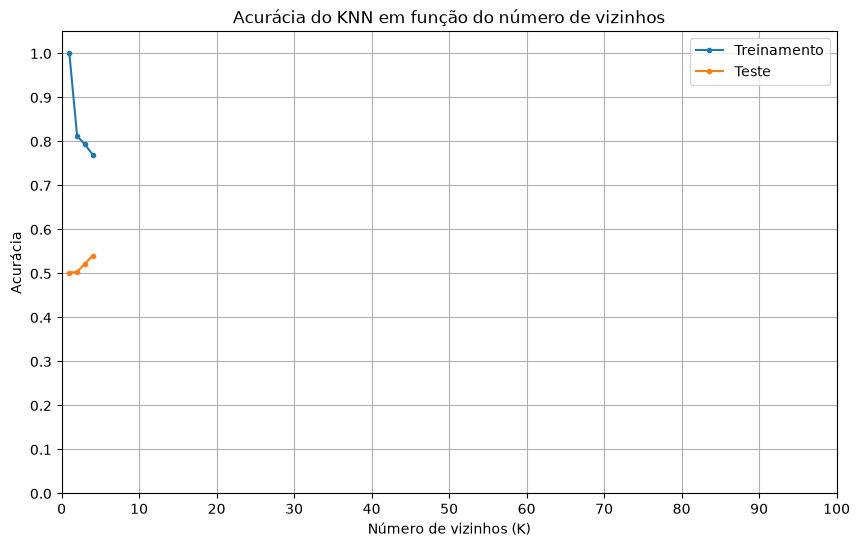

In [6]:
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from imblearn.over_sampling import SMOTE
import numpy as np
import matplotlib.pyplot as plt

encoder_data = MinMaxScaler()
encoder_class = LabelEncoder()
balanceamento = SMOTE(random_state=42)

X = df_dataset.select_dtypes(include="number")
Y = df_dataset["class"]

# Codificação das classes
y_encoded = encoder_class.fit_transform(Y)

# Separação entre treinamento e teste
X_train, X_test, y_train, y_test = train_test_split(
    X.iloc[:, 2:3],
    y_encoded,
    test_size=0.3,
    random_state=0,
    stratify=y_encoded
)

# Normalização
X_train = encoder_data.fit_transform(X_train)
X_test = encoder_data.transform(X_test)

# Balanceamento somente do conjunto de treinamento
X_train_resampled, y_train_resampled = balanceamento.fit_resample(
    X_train,
    y_train
)

# Valores de K
valores_k = range(1, 5)

acuracias_treino = []
acuracias_teste = []

for k in valores_k:

    modelo = KNeighborsClassifier(
        n_neighbors=k
    )

    modelo.fit(X_train_resampled, y_train_resampled)

    # Acurácia no treinamento
    y_train_pred = modelo.predict(X_train_resampled)
    acc_train = accuracy_score(
        y_train_resampled,
        y_train_pred
    )

    # Acurácia no teste
    y_test_pred = modelo.predict(X_test)
    acc_test = accuracy_score(
        y_test,
        y_test_pred
    )

    acuracias_treino.append(acc_train)
    acuracias_teste.append(acc_test)

# Gráfico
plt.figure(figsize=(10, 6))

plt.plot(
    valores_k,
    acuracias_treino,
    marker="o",
    markersize=3,
    label="Treinamento"
)

plt.plot(
    valores_k,
    acuracias_teste,
    marker="o",
    markersize=3,
    label="Teste"
)

plt.xlabel("Número de vizinhos (K)")
plt.ylabel("Acurácia")
plt.title("Acurácia do KNN em função do número de vizinhos")

plt.ylim(0, 1.05)
plt.yticks(np.arange(0, 1.1, 0.1))
plt.xticks(np.arange(0, 101, 10))

plt.grid()
plt.legend()

plt.show()

In [8]:
X.iloc[:, 2:3]

,I_kurtosis
0,2.712868
1,2.782580
2,2.708843
3,2.786911
4,2.761420
...,...
13825,2.426086
13826,2.438967
13827,2.539186
13828,2.433208


<h1>KNN<h1>

In [229]:
pipeline_machineLearning = Pipeline([
    ("modelo", KNeighborsClassifier())
])

param_grid = [
    {
        "modelo":[KNeighborsClassifier()],
        "modelo__n_neighbors": np.arange(1,100,2)
    }
]

grid_search = GridSearchCV(
    pipeline_machineLearning,
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train_resampled, y_train_resampled)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'modelo': [KNeighborsClassifier()], 'modelo__n_neighbors': array([ 1, 3..., 95, 97, 99])}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0

In [230]:
y_train_pred = grid_search.predict(X_train_resampled)
y_test_pred = grid_search.predict(X_test)
printDesempenho(y_train_resampled, y_train_pred, y_test, y_test_pred, encoder_class)

TREINAMENTO:
              precision    recall  f1-score   support

     Bearing       1.00      1.00      1.00      4158
   Imbalance       1.00      1.00      1.00      4158
      Normal       1.00      1.00      1.00      4158
       Rotor       1.00      1.00      1.00      4158
       Wound       1.00      1.00      1.00      4158

    accuracy                           1.00     20790
   macro avg       1.00      1.00      1.00     20790
weighted avg       1.00      1.00      1.00     20790

TESTE:
              precision    recall  f1-score   support

     Bearing       0.99      0.99      0.99       594
   Imbalance       0.99      0.99      0.99      1782
      Normal       1.00      1.00      1.00       594
       Rotor       0.99      1.00      1.00       594
       Wound       1.00      1.00      1.00       585

    accuracy                           1.00      4149
   macro avg       1.00      1.00      1.00      4149
weighted avg       1.00      1.00      1.00      4149



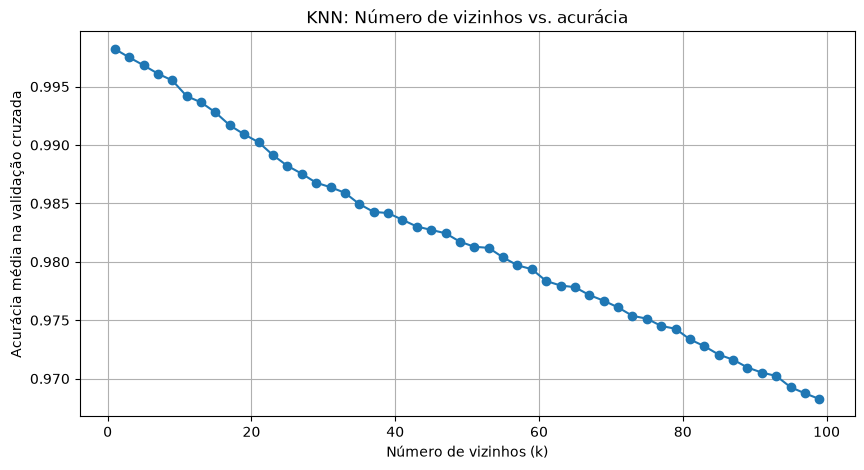

In [231]:
results = pd.DataFrame(grid_search.cv_results_)

plt.figure(figsize=(10, 5))

plt.plot(
    results["param_modelo__n_neighbors"],
    results["mean_test_score"],
    marker="o"
)

plt.xlabel("Número de vizinhos (k)")
plt.ylabel("Acurácia média na validação cruzada")
plt.title("KNN: Número de vizinhos vs. acurácia")
plt.grid()
plt.show()

(13830, 28)

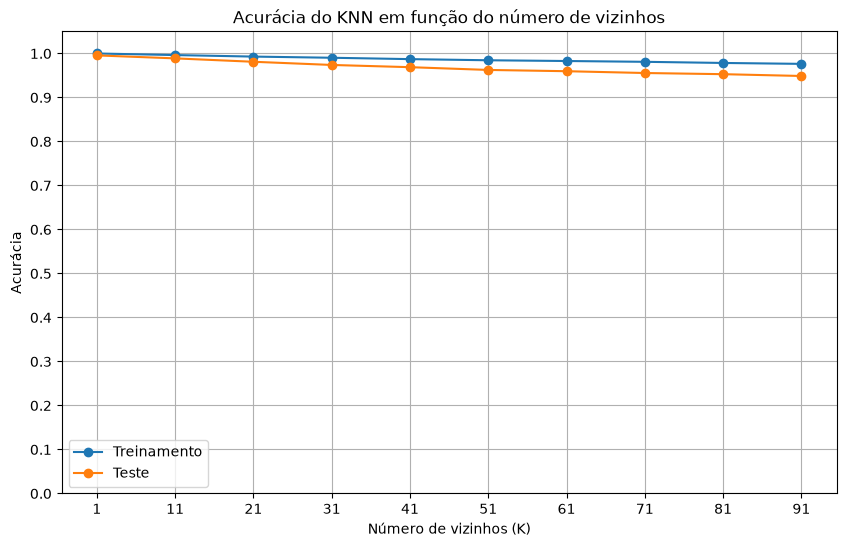

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

valores_k = range(1,100, 10)

acuracias_treino = []
acuracias_teste = []

for k in valores_k:

    modelo = KNeighborsClassifier(
        n_neighbors=k
    )

    modelo.fit(X_train_resampled, y_train_resampled)

    # Acurácia no treinamento
    y_train_pred = modelo.predict(X_train_resampled)
    acc_train = accuracy_score(y_train_resampled, y_train_pred)

    # Acurácia no teste
    y_test_pred = modelo.predict(X_test)
    acc_test = accuracy_score(y_test, y_test_pred)

    acuracias_treino.append(acc_train)
    acuracias_teste.append(acc_test)

# Gráfico
plt.figure(figsize=(10, 6))

plt.plot(
    valores_k,
    acuracias_treino,
    marker="o",
    label="Treinamento"
)

plt.plot(
    valores_k,
    acuracias_teste,
    marker="o",
    label="Teste"
)

plt.xlabel("Número de vizinhos (K)")
plt.ylabel("Acurácia")
plt.title("Acurácia do KNN em função do número de vizinhos")
plt.ylim(0, 1.05)
plt.yticks(np.arange(0, 1.1, 0.1))
plt.xticks(valores_k)
plt.grid()
plt.legend()

plt.show()

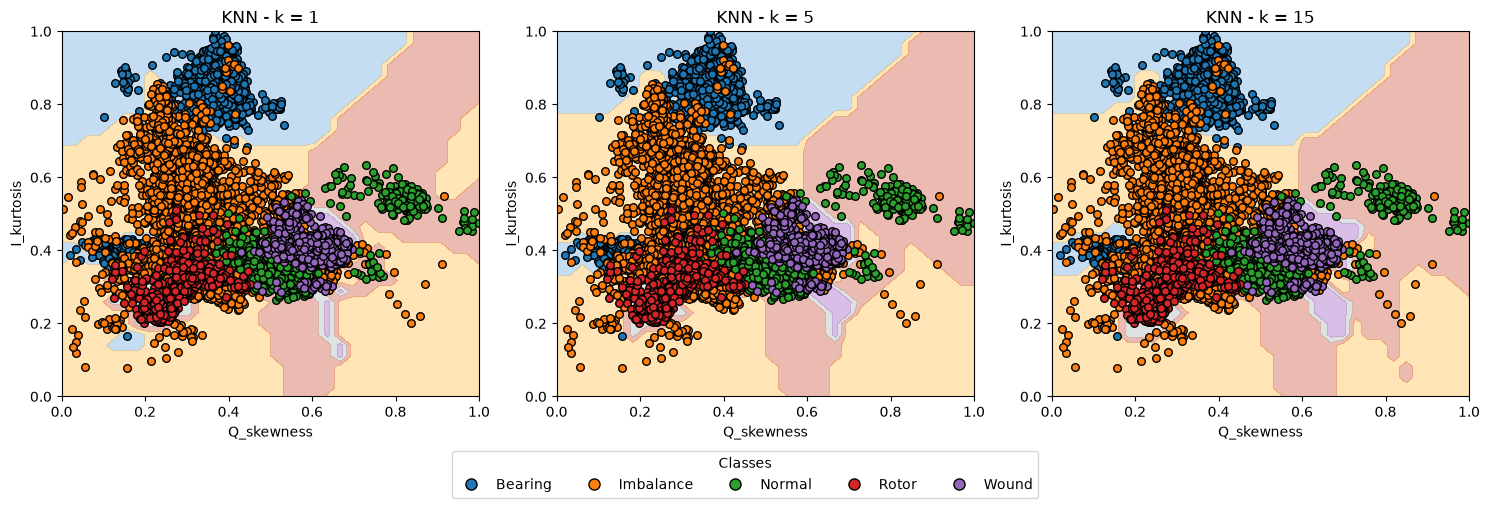

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

feature1 = "Q_skewness"
feature2 = "I_kurtosis"

features = X.columns.tolist()

idx_f1 = features.get_loc(feature1) if hasattr(features, 'get_loc') else features.index(feature1)
idx_f2 = features.get_loc(feature2) if hasattr(features, 'get_loc') else features.index(feature2)

X_2d = X_train[:, [idx_f1, idx_f2]]

valores_k = [1, 5, 15]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Cores fixas para as classes
cores = plt.cm.tab10(np.arange(len(encoder_class.classes_)))

for ax, k in zip(axes, valores_k):

    modelo_knn = KNeighborsClassifier(
        n_neighbors=k
    )

    modelo_knn.fit(X_2d, y_train)

    DecisionBoundaryDisplay.from_estimator(
        modelo_knn,
        X_2d,
        response_method="predict",
        alpha=0.3,
        ax=ax
    )

    # Pontos das amostras
    for classe in np.unique(y_train):

        mask = y_train == classe

        ax.scatter(
            X_2d[mask, 0],
            X_2d[mask, 1],
            color=cores[classe],
            edgecolor="k",
            s=30
        )

    ax.set_title(f"KNN - k = {k}")
    ax.set_xlabel(feature1)
    ax.set_ylabel(feature2)

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

# Criar legenda única
handles = []

for i, classe in enumerate(encoder_class.classes_):

    handles.append(
        Line2D(
            [0],
            [0],
            marker="o",
            linestyle="",
            markerfacecolor=cores[i],
            markeredgecolor="k",
            markersize=8,
            label=classe
        )
    )

fig.legend(
    handles=handles,
    title="Classes",
    loc="lower center",
    ncol=len(handles),
    bbox_to_anchor=(0.5, -0.02)
)

plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()